In [ ]:
!pip install -q transformers accelerate sentencepiece

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import torch

from transformers import pipeline
from tqdm.auto import tqdm

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
project_path = "/content/drive/MyDrive/olist-ecommerce-intelligence"

In [ ]:
print(os.path.exists(project_path))

True


In [ ]:
raw_path = os.path.join(
    project_path, "data", "raw"
)

processed_path = os.path.join(
    project_path, "data", "processed"
)

notebook_path = os.path.join(
    project_path, "notebooks"
)

visualization_path = os.path.join(
    project_path, "visualizations"
)

os.makedirs(processed_path, exist_ok=True)
os.makedirs(visualization_path, exist_ok=True)

print("Project paths created successfully!")

Project paths created successfully!


In [ ]:
reviews = pd.read_csv(
    os.path.join(
        raw_path,
        "olist_order_reviews_dataset.csv"
    )
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Rows and columns:", reviews.shape)

reviews.head()

Rows and columns: (99224, 7)


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [ ]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [ ]:
reviews["review_score"].value_counts().sort_index()

,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


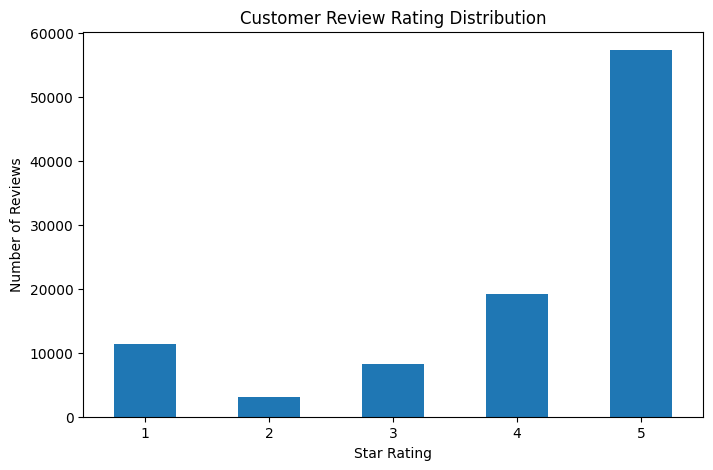

In [ ]:
rating_counts = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
)

rating_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Review Rating Distribution")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

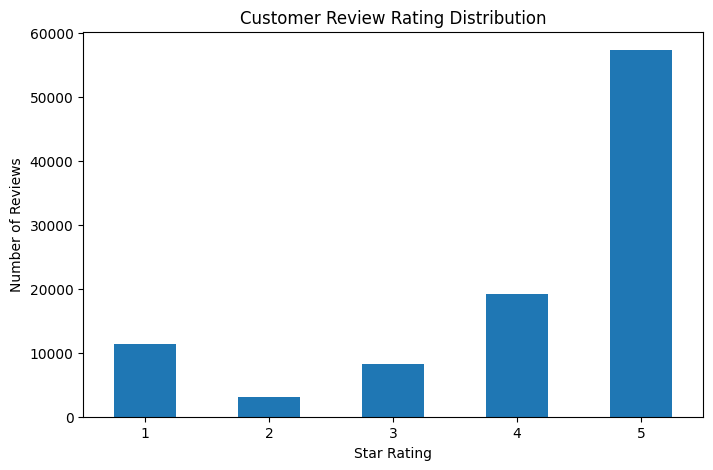

In [ ]:
rating_counts = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
)

rating_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Review Rating Distribution")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

In [ ]:
text_reviews = reviews.copy()

text_reviews["review_comment_message"] = (
    text_reviews["review_comment_message"]
    .fillna("")
    .astype(str)
    .str.strip()
)

In [ ]:
text_reviews = text_reviews[
    text_reviews["review_comment_message"] != ""
].copy()

In [ ]:
print("Total original reviews:", len(reviews))

print("Reviews with written comments:", len(text_reviews))

print("Empty comments remaining:",
      (text_reviews["review_comment_message"] == "").sum())

Total original reviews: 99224
Reviews with written comments: 40950
Empty comments remaining: 0


In [ ]:
text_reviews[
    ["review_score", "review_comment_message"]
].head(15)

,review_score,review_comment_message
3,5,Recebi bem antes do prazo estipulado.
4,5,Parabéns lojas lannister adorei comprar pela I...
9,4,aparelho eficiente. no site a marca do aparelh...
12,4,"Mas um pouco ,travando...pelo valor ta Boa."
15,5,"Vendedor confiável, produto ok e entrega antes..."
16,2,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E..."
19,1,Péssimo
22,5,Loja nota 10
24,5,obrigado pela atençao amim dispensada
27,5,A compra foi realizada facilmente.\r\nA entreg...


In [ ]:
model_name = "Horizon-Labs/multilingual-sentiment-small"

sentiment_model = pipeline(
    "text-classification",
    model=model_name,
    tokenizer=model_name,
    device=0 if torch.cuda.is_available() else -1
)

print("AI sentiment model loaded successfully!")

config.json:   0%|          | 0.00/2.08k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  563MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/46.4k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 34.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

AI sentiment model loaded successfully!


In [ ]:
print(
    "GPU available:",
    torch.cuda.is_available()
)

GPU available: False


In [ ]:
sample_comments = [
    "O produto é excelente, gostei muito!",
    "O produto chegou quebrado e estou muito insatisfeito.",
    "O produto chegou ontem.",
    "A entrega foi rápida e o produto é ótimo.",
    "A entrega atrasou muito e o atendimento foi péssimo."
]

In [ ]:
sample_predictions = sentiment_model(
    sample_comments,
    truncation=True
)

for comment, prediction in zip(
    sample_comments,
    sample_predictions
):
    print("Comment:", comment)
    print("AI Sentiment:", prediction["label"])
    print("Confidence:", round(prediction["score"], 3))
    print("-" * 50)

Comment: O produto é excelente, gostei muito!
AI Sentiment: positive
Confidence: 1.0
--------------------------------------------------
Comment: O produto chegou quebrado e estou muito insatisfeito.
AI Sentiment: negative
Confidence: 0.999
--------------------------------------------------
Comment: O produto chegou ontem.
AI Sentiment: neutral
Confidence: 0.93
--------------------------------------------------
Comment: A entrega foi rápida e o produto é ótimo.
AI Sentiment: positive
Confidence: 0.999
--------------------------------------------------
Comment: A entrega atrasou muito e o atendimento foi péssimo.
AI Sentiment: negative
Confidence: 1.0
--------------------------------------------------


In [ ]:
print(sentiment_model.model.config.id2label)

{0: 'negative', 1: 'neutral', 2: 'positive'}


In [ ]:
print(sample_predictions)

[{'label': 'positive', 'score': 0.9999505281448364}, {'label': 'negative', 'score': 0.9993367791175842}, {'label': 'neutral', 'score': 0.9296919703483582}, {'label': 'positive', 'score': 0.9986868500709534}, {'label': 'negative', 'score': 0.9996730089187622}]


In [ ]:
print("Model label mapping:")
print(sentiment_model.model.config.id2label)

Model label mapping:
{0: 'negative', 1: 'neutral', 2: 'positive'}


In [ ]:
sample_results = pd.DataFrame({
    "Customer Comment": sample_comments,
    "AI Sentiment": [
        p["label"] for p in sample_predictions
    ],
    "AI Confidence": [
        round(p["score"], 3) for p in sample_predictions
    ]
})

sample_results

,Customer Comment,AI Sentiment,AI Confidence
0,"O produto é excelente, gostei muito!",positive,1.000
1,O produto chegou quebrado e estou muito insati...,negative,0.999
2,O produto chegou ontem.,neutral,0.930
3,A entrega foi rápida e o produto é ótimo.,positive,0.999
4,A entrega atrasou muito e o atendimento foi pé...,negative,1.000


In [ ]:
pilot_reviews = text_reviews.head(100).copy()

pilot_texts = (
    pilot_reviews["review_comment_message"].tolist()
)

pilot_predictions = sentiment_model(
    pilot_texts,
    batch_size=16,
    truncation=True,
    max_length=512
)

In [ ]:
pilot_reviews["ai_sentiment"] = [
    p["label"].lower()
    for p in pilot_predictions
]

pilot_reviews["ai_confidence"] = [
    p["score"]
    for p in pilot_predictions
]

pilot_reviews[
    [
        "review_score",
        "review_comment_message",
        "ai_sentiment",
        "ai_confidence"
    ]
].head(20)

,review_score,review_comment_message,ai_sentiment,ai_confidence
3,5,Recebi bem antes do prazo estipulado.,positive,0.657523
4,5,Parabéns lojas lannister adorei comprar pela I...,positive,0.990118
9,4,aparelho eficiente. no site a marca do aparelh...,neutral,0.775610
12,4,"Mas um pouco ,travando...pelo valor ta Boa.",neutral,0.535968
15,5,"Vendedor confiável, produto ok e entrega antes...",positive,0.983629
16,2,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E...",positive,0.851199
19,1,Péssimo,neutral,0.464108
22,5,Loja nota 10,neutral,0.507368
24,5,obrigado pela atençao amim dispensada,positive,0.618268
27,5,A compra foi realizada facilmente.\r\nA entreg...,positive,0.975177


In [ ]:
review_texts = (
    text_reviews["review_comment_message"]
    .tolist()
)

print("Total comments for AI:", len(review_texts))

Total comments for AI: 40950


In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    print("Currently using CPU")

GPU available: False
Currently using CPU


In [ ]:
from tqdm.auto import tqdm

progress_file = os.path.join(
    processed_path,
    "olist_ai_progress.csv"
)

if os.path.exists(progress_file):
    progress_df = pd.read_csv(progress_file)
    start_index = len(progress_df)
else:
    progress_df = text_reviews.iloc[0:0].copy()
    start_index = 0

print("Already processed:", start_index)
print("Remaining:", len(text_reviews) - start_index)

Already processed: 40950
Remaining: 0


In [ ]:
batch_size = 32 if torch.cuda.is_available() else 8
chunk_size = 1000

for start in tqdm(
    range(start_index, len(text_reviews), chunk_size)
):

    end = min(start + chunk_size, len(text_reviews))

    batch_texts = (
        text_reviews["review_comment_message"]
        .iloc[start:end]
        .tolist()
    )

    batch_predictions = sentiment_model(
        batch_texts,
        batch_size=batch_size,
        truncation=True,
        max_length=256
    )

    chunk_df = text_reviews.iloc[start:end].copy()

    chunk_df["ai_sentiment"] = [
        p["label"].lower()
        for p in batch_predictions
    ]

    chunk_df["ai_confidence"] = [
        p["score"]
        for p in batch_predictions
    ]

    progress_df = pd.concat(
        [progress_df, chunk_df],
        ignore_index=True
    )

    progress_df.to_csv(
        progress_file,
        index=False
    )

print("AI processing completed!")

0it [00:00, ?it/s]

AI processing completed!


In [65]:
all_predictions = []

batch_size = 32
chunk_size = 1000

for start in tqdm(
    range(0, len(review_texts), chunk_size)
):

    batch_texts = review_texts[
        start:start + chunk_size
    ]

    batch_predictions = sentiment_model(
        batch_texts,
        batch_size=batch_size,
        truncation=True,
        max_length=512
    )

    all_predictions.extend(batch_predictions)

    # Save progress after every chunk
    progress_df = text_reviews.iloc[
        :len(all_predictions)
    ].copy()

    progress_df["ai_sentiment"] = [
        p["label"].lower()
        for p in all_predictions
    ]

    progress_df["ai_confidence"] = [
        p["score"]
        for p in all_predictions
    ]

    progress_df.to_csv(
        os.path.join(
            processed_path,
            "olist_ai_progress.csv"
        ),
        index=False
    )

print("AI analysis completed!")

  0%|          | 0/41 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [66]:
progress_file = os.path.join(
    processed_path,
    "olist_ai_progress.csv"
)

if os.path.exists(progress_file):
    saved_progress = pd.read_csv(progress_file)

    print("Saved reviews:", len(saved_progress))
    print("Total written reviews:", len(text_reviews))
    print("Saved percentage:", round(
        len(saved_progress) / len(text_reviews) * 100, 2
    ), "%")
    print("Columns:", saved_progress.columns.tolist())
else:
    print("No saved progress file found.")

Saved reviews: 40950
Total written reviews: 40950
Saved percentage: 100.0 %
Columns: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp', 'ai_sentiment', 'ai_confidence']


In [68]:
text_reviews_ai = pd.read_csv(progress_file)

print("Total AI-analysed reviews:", len(text_reviews_ai))
print("\nSentiment counts:")
print(text_reviews_ai["ai_sentiment"].value_counts())

print("\nFirst 5 results:")
display(
    text_reviews_ai[
        ["review_score", "review_comment_message",
         "ai_sentiment", "ai_confidence"]
    ].head()
)

Total AI-analysed reviews: 40950

Sentiment counts:
ai_sentiment
positive    21312
negative    10251
neutral      9387
Name: count, dtype: int64

First 5 results:


,review_score,review_comment_message,ai_sentiment,ai_confidence
0,5,Recebi bem antes do prazo estipulado.,positive,0.657523
1,5,Parabéns lojas lannister adorei comprar pela I...,positive,0.990118
2,4,aparelho eficiente. no site a marca do aparelh...,neutral,0.775610
3,4,"Mas um pouco ,travando...pelo valor ta Boa.",neutral,0.535968
4,5,"Vendedor confiável, produto ok e entrega antes...",positive,0.983629


In [69]:
sentiment_mapping = {
    "positive": "Happy",
    "neutral": "Neutral",
    "negative": "Unhappy"
}

text_reviews_ai["customer_mood"] = (
    text_reviews_ai["ai_sentiment"].map(sentiment_mapping)
)

emoji_mapping = {
    "Happy": "😊",
    "Neutral": "😐",
    "Unhappy": "☹️"
}

text_reviews_ai["mood_icon"] = (
    text_reviews_ai["customer_mood"].map(emoji_mapping)
)

display(
    text_reviews_ai[
        ["review_score", "ai_sentiment",
         "customer_mood", "mood_icon"]
    ].head(10)
)

,review_score,ai_sentiment,customer_mood,mood_icon
0,5,positive,Happy,😊
1,5,positive,Happy,😊
2,4,neutral,Neutral,😐
3,4,neutral,Neutral,😐
4,5,positive,Happy,😊
5,2,positive,Happy,😊
6,1,neutral,Neutral,😐
7,5,neutral,Neutral,😐
8,5,positive,Happy,😊
9,5,positive,Happy,😊


In [70]:
sentiment_summary = (
    text_reviews_ai["customer_mood"]
    .value_counts()
    .rename_axis("Customer Mood")
    .reset_index(name="Review Count")
)

sentiment_summary["Percentage"] = (
    sentiment_summary["Review Count"]
    / sentiment_summary["Review Count"].sum()
    * 100
).round(2)

display(sentiment_summary)

,Customer Mood,Review Count,Percentage
0,Happy,21312,52.04
1,Unhappy,10251,25.03
2,Neutral,9387,22.92


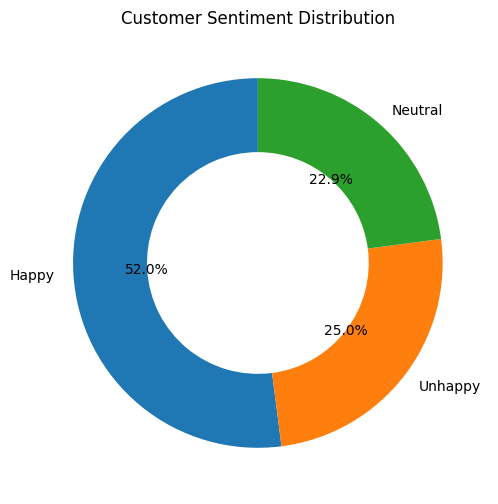

In [71]:
plt.figure(figsize=(8, 6))

plt.pie(
    sentiment_summary["Review Count"],
    labels=sentiment_summary["Customer Mood"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Customer Sentiment Distribution")
plt.show()

In [72]:
print(
    "Average AI confidence:",
    round(text_reviews_ai["ai_confidence"].mean(), 4)
)

print("\nConfidence by sentiment:")

display(
    text_reviews_ai.groupby("ai_sentiment")["ai_confidence"]
    .agg(["mean", "median", "min", "max", "count"])
    .round(3)
)

Average AI confidence: 0.879

Confidence by sentiment:


,mean,median,min,max,count
ai_sentiment,,,,,
negative,0.857,0.923,0.351,1.0,10251
neutral,0.762,0.783,0.360,1.0,9387
positive,0.941,0.994,0.344,1.0,21312


In [73]:
def rating_category(score):

    if score <= 2:
        return "Negative"

    elif score == 3:
        return "Neutral"

    else:
        return "Positive"

In [74]:
text_reviews_ai["rating_sentiment"] = (
    text_reviews_ai["review_score"]
    .apply(rating_category)
)

In [75]:
sentiment_comparison = pd.crosstab(
    text_reviews_ai["rating_sentiment"],
    text_reviews_ai["ai_sentiment"]
)

sentiment_comparison

ai_sentiment,negative,neutral,positive
rating_sentiment,,,
Negative,7874,2691,324
Neutral,1324,1576,656
Positive,1053,5120,20332


In [76]:
sentiment_comparison_percentage = (
    pd.crosstab(
        text_reviews_ai["rating_sentiment"],
        text_reviews_ai["ai_sentiment"],
        normalize="index"
    ) * 100
).round(2)

sentiment_comparison_percentage

ai_sentiment,negative,neutral,positive
rating_sentiment,,,
Negative,72.31,24.71,2.98
Neutral,37.23,44.32,18.45
Positive,3.97,19.32,76.71


In [77]:
final_ai_file = os.path.join(
    processed_path,
    "olist_ai_sentiment_results.csv"
)

text_reviews_ai.to_csv(
    final_ai_file,
    index=False
)

print("Final AI dataset saved!")
print(final_ai_file)

Final AI dataset saved!
/content/drive/MyDrive/olist-ecommerce-intelligence/data/processed/olist_ai_sentiment_results.csv


In [80]:
# Convert star ratings into three comparison groups

text_reviews_ai["rating_sentiment"] = np.where(
    text_reviews_ai["review_score"] <= 2,
    "negative",
    np.where(
        text_reviews_ai["review_score"] == 3,
        "neutral",
        "positive"
    )
)

# Compare AI sentiment with star-rating sentiment

text_reviews_ai["sentiment_agreement"] = (
    text_reviews_ai["rating_sentiment"]
    == text_reviews_ai["ai_sentiment"]
)

print("Agreement summary:")
print(
    text_reviews_ai["sentiment_agreement"].value_counts()
)

print("\nAgreement percentage:")
print(
    round(
        text_reviews_ai["sentiment_agreement"].mean() * 100,
        2
    ),
    "%"
)

Agreement summary:
sentiment_agreement
True     29782
False    11168
Name: count, dtype: int64

Agreement percentage:
72.73 %


In [81]:
disagreements = text_reviews_ai[
    text_reviews_ai["sentiment_agreement"] == False
]

display(
    disagreements[
        [
            "review_score",
            "review_comment_message",
            "rating_sentiment",
            "ai_sentiment",
            "ai_confidence"
        ]
    ].sample(
        min(20, len(disagreements)),
        random_state=42
    )
)

,review_score,review_comment_message,rating_sentiment,ai_sentiment,ai_confidence
37601,5,"Infelizmente não fui eu a receber, mas foi ent...",positive,negative,0.964301
38329,5,Top,positive,neutral,0.995182
36187,3,"Recebi tudo normal, só que o produto não esta ...",neutral,negative,0.700295
22882,3,Não recebemos a mercadoria até hoje,neutral,negative,0.639190
32492,4,tudo certo,positive,neutral,0.553695
30846,3,Quando da compra me foi dito que o produto ser...,neutral,negative,0.831245
17012,1,Preciso saber da data de entrega pois até agor...,negative,neutral,0.637965
23263,3,"Chegou no prazo, porém amassada! Muito amassad...",neutral,negative,0.959178
20576,5,Aguardo o meu sofá que comprei antes para entr...,positive,negative,0.979340
18902,4,"Sempre fui bem atendida, entregaram no prazo.\...",positive,neutral,0.599038


In [82]:
unhappy_reviews = text_reviews_ai[
    text_reviews_ai["ai_sentiment"] == "negative"
].copy()

print("Total unhappy reviews:", len(unhappy_reviews))

display(
    unhappy_reviews[
        ["review_score", "review_comment_message", "ai_confidence"]
    ].head(10)
)

Total unhappy reviews: 10251


,review_score,review_comment_message,ai_confidence
11,1,Não gostei ! Comprei gato por lebre,0.874852
12,1,Sempre compro pela Internet e a entrega ocorre...,0.815738
17,1,Nada de chegar o meu pedido.,0.786263
21,5,Tomara q dure pois é de pelinho.,0.377359
29,1,O produto não chegou no prazo estipulado e cau...,0.950566
31,3,Eu comprei duas unidades e só recebi uma e ago...,0.923624
33,1,"Produto muito inferior, mal acabado.",0.999502
38,1,Pedi reembolso e sem resposta até momento,0.979436
43,3,"Produto chegou, mas meu PC não conseguiu recon...",0.603038
50,2,Demorou de mais pra entrega,0.652303


In [83]:
import re

complaint_keywords = {
    "Delivery Issues": [
        "atras", "demor", "prazo", "entrega",
        "não recebi", "nao recebi", "não chegou",
        "nao chegou", "aguardo", "extravio"
    ],

    "Product Quality": [
        "defeito", "quebrad", "danificad",
        "não funciona", "nao funciona",
        "problema", "péssimo", "pessimo"
    ],

    "Wrong Product": [
        "produto errado", "veio errado",
        "pedido errado", "cor errada",
        "tamanho errado", "modelo errado"
    ],

    "Packaging Issues": [
        "embalagem", "amassad", "rasgad",
        "pacote aberto", "mal embalado"
    ],

    "Refund and Returns": [
        "reembolso", "devolução", "devolucao",
        "estorno", "troca", "cancelamento"
    ],

    "Customer Service": [
        "atendimento", "vendedor", "loja",
        "resposta", "contato", "suporte"
    ],

    "Missing Items": [
        "faltando", "não veio", "nao veio",
        "item faltando", "peça faltando",
        "peca faltando"
    ],

    "Product Information": [
        "manual", "garantia", "descrição",
        "descricao", "diferente do anunciado"
    ]
}

In [84]:
def identify_themes(comment):

    comment = str(comment).lower()

    matched_themes = []

    for theme, keywords in complaint_keywords.items():

        if any(keyword in comment for keyword in keywords):
            matched_themes.append(theme)

    return matched_themes


unhappy_reviews["complaint_themes"] = (
    unhappy_reviews["review_comment_message"]
    .apply(identify_themes)
)

display(
    unhappy_reviews[
        ["review_comment_message", "complaint_themes"]
    ].head(20)
)

,review_comment_message,complaint_themes
11,Não gostei ! Comprei gato por lebre,[]
12,Sempre compro pela Internet e a entrega ocorre...,[Delivery Issues]
17,Nada de chegar o meu pedido.,[]
21,Tomara q dure pois é de pelinho.,[]
29,O produto não chegou no prazo estipulado e cau...,[Delivery Issues]
31,Eu comprei duas unidades e só recebi uma e ago...,[]
33,"Produto muito inferior, mal acabado.",[]
38,Pedi reembolso e sem resposta até momento,"[Refund and Returns, Customer Service]"
43,"Produto chegou, mas meu PC não conseguiu recon...",[]
50,Demorou de mais pra entrega,[Delivery Issues]


In [85]:
from collections import Counter

theme_counts = Counter()

for themes in unhappy_reviews["complaint_themes"]:
    theme_counts.update(themes)

theme_summary = pd.DataFrame(
    theme_counts.items(),
    columns=["Complaint Theme", "Review Count"]
)

theme_summary = theme_summary.sort_values(
    by="Review Count",
    ascending=False
)

display(theme_summary)

,Complaint Theme,Review Count
0,Delivery Issues,4352
2,Customer Service,1673
3,Product Quality,1225
1,Refund and Returns,927
5,Missing Items,394
4,Packaging Issues,324
6,Wrong Product,230
7,Product Information,184


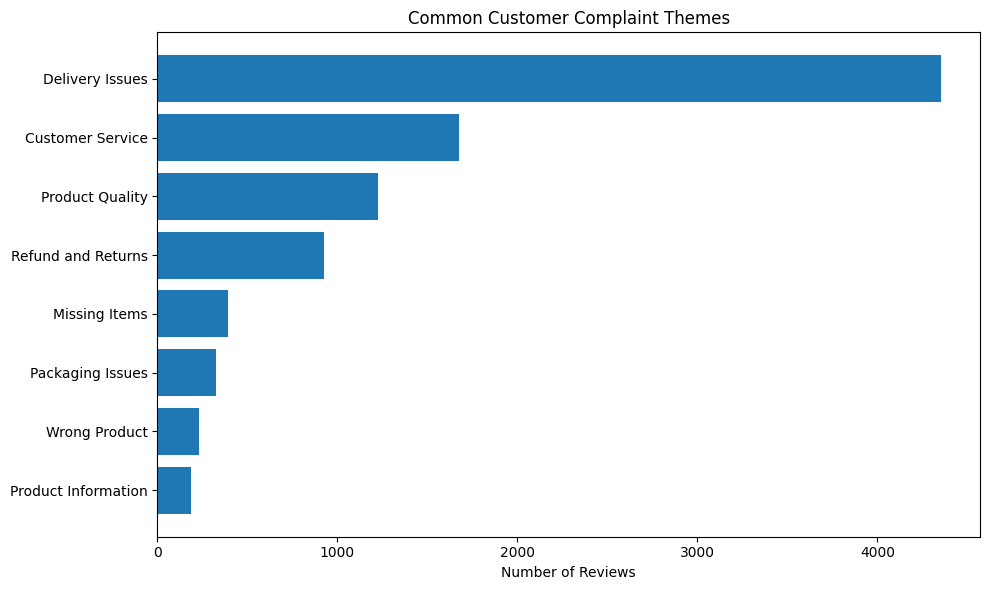

In [86]:
plt.figure(figsize=(10, 6))

plt.barh(
    theme_summary["Complaint Theme"],
    theme_summary["Review Count"]
)

plt.xlabel("Number of Reviews")
plt.title("Common Customer Complaint Themes")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [87]:
theme_summary["Percentage_of_Unhappy_Reviews"] = (
    theme_summary["Review Count"]
    / len(unhappy_reviews)
    * 100
).round(2)

display(theme_summary)

,Complaint Theme,Review Count,Percentage_of_Unhappy_Reviews
0,Delivery Issues,4352,42.45
2,Customer Service,1673,16.32
3,Product Quality,1225,11.95
1,Refund and Returns,927,9.04
5,Missing Items,394,3.84
4,Packaging Issues,324,3.16
6,Wrong Product,230,2.24
7,Product Information,184,1.79


In [88]:
for theme in complaint_keywords.keys():

    print("\n" + "=" * 60)
    print("THEME:", theme)
    print("=" * 60)

    theme_examples = unhappy_reviews[
        unhappy_reviews["complaint_themes"].apply(
            lambda x: theme in x
        )
    ]

    display(
        theme_examples[
            ["review_score", "review_comment_message"]
        ].sample(
            min(5, len(theme_examples)),
            random_state=42
        )
    )


THEME: Delivery Issues


,review_score,review_comment_message
5132,2,Depois de mais de 25 dias constatei pelo site ...
15330,1,Estou com um cancelamento em aberto e o prazo ...
29385,1,"Entrega no prazo, mas não serviu para o meu Ca..."
5193,1,"Fornecedor péssimo, não recebi meu produto até..."
14062,1,Fora do prazo combinado.... Não compro mais ne...



THEME: Product Quality


,review_score,review_comment_message
20004,1,Produto não acompanha quaisquer desenho de mon...
24346,1,Recebi meu produto totalmente quebrado. Não se...
30764,1,Não recebi e não tive ainda uma solução do pro...
38398,1,"Eu não recebi a mochila, não sei se o problema..."
14092,1,estou tendo problemas com a entrega do produto...



THEME: Wrong Product


,review_score,review_comment_message
38654,1,O único problema que eu tive foi ter recebido ...
12733,4,Recebi a cor errada
1318,1,Sinceramente comprei uma navalha e um kit teso...
33556,1,Estou há mais de 30 dias para devolver este pr...
2228,1,O produto veio errado. o que é um transtorno v...


... (6 outputs left out)


THEME: Missing Items


,review_score,review_comment_message
8046,1,"meu produto não veio, voltou para São Paulo/SP..."
29005,1,"Pedi 2 pulseiras e 3 colares, todos para dar d..."
26128,2,Bom diameu pedido veio faltando 1 kit de cabid...
5273,1,O produto veio com peças faltando. Não consigo...
40773,2,eu recebi e fiquei com a mercadoria porque est...



THEME: Product Information


,review_score,review_comment_message
5436,4,Na minha opinião faltou o manual de instrução ...
10779,1,"Não recebemos as notas dos produtos, como isso..."
34828,3,O produto enviado não condiz com a descrição.\...
26544,1,"Produto de péssima qualidade, muito diferente ..."
33838,3,muito difcil entrar com a assistncia de garant...


In [89]:
unclassified_reviews = unhappy_reviews[
    unhappy_reviews["complaint_themes"].apply(
        lambda x: len(x) == 0
    )
]

print("Total unhappy reviews:", len(unhappy_reviews))
print("Classified reviews:", len(unhappy_reviews) - len(unclassified_reviews))
print("Unclassified reviews:", len(unclassified_reviews))

print(
    "Unclassified percentage:",
    round(
        len(unclassified_reviews) / len(unhappy_reviews) * 100,
        2
    ),
    "%"
)

display(
    unclassified_reviews[
        ["review_score", "review_comment_message"]
    ].sample(
        min(15, len(unclassified_reviews)),
        random_state=42
    )
)

Total unhappy reviews: 10251
Classified reviews: 6950
Unclassified reviews: 3301
Unclassified percentage: 32.2 %


,review_score,review_comment_message
551,2,produto entregue totalmente diferente do comprado
8537,1,Não mandaram o produto e nem deram satisfação.
15806,2,Custa muito
20249,2,Péssima estou aguardando a mercadoria até hoje...
2599,1,Comprei um relógio Oakley Minute Machine e che...
30567,1,"Pedi dois kit veio so um, fora que eu paguei p..."
25937,4,Não recebeu o produto HP
30868,1,O produto chegou totalmente riscado e sem cond...
20877,1,infelizmente não fui feliz ao realizar essa co...
6306,1,Comprei 04 jogos de lençóis de cetim. Recebi s...


In [94]:
import unicodedata

complaint_keywords = {
    "Delivery Issues": [
        "atras", "demor", "prazo", "entrega",
        "nao recebi", "nao chegou", "aguardo",
        "extravio", "mercadoria ate hoje",
        "nao mandaram", "nao entregaram"
    ],

    "Product Quality": [
        "defeito", "quebrad", "danificad",
        "nao funciona", "problema",
        "pessimo", "baixa qualidade",
        "material fragil", "riscado",
        "mal acabado"
    ],

    "Wrong Product": [
        "produto errado", "veio errado",
        "pedido errado", "cor errada",
        "tamanho errado", "modelo errado",
        "diferente do comprado",
        "diferente do produto"
    ],

    "Packaging Issues": [
        "embalagem", "amassad", "rasgad",
        "pacote aberto", "mal embalado"
    ],

    "Refund and Returns": [
        "reembolso", "devolucao", "estorno",
        "troca", "cancelamento", "devolver"
    ],

    "Customer Service": [
        "atendimento", "vendedor", "loja",
        "resposta", "contato", "suporte",
        "nao deram satisfacao",
        "mais atencao"
    ],

    "Missing Items": [
        "faltando", "nao veio",
        "item faltando", "pecas faltando",
        "so recebi um", "recebi apenas um",
        "faltou", "nao mandaram o produto"
    ],

    "Product Information": [
        "manual", "garantia", "descricao",
        "diferente do anunciado",
        "nota fiscal", "assistencia"
    ],

    "Price and Value": [
        "caro", "custa muito",
        "pelo preco", "valor pago"
    ]
}

In [95]:
def normalize_text(text):
    text = str(text).lower()

    text = unicodedata.normalize("NFKD", text)

    text = "".join(
        char for char in text
        if not unicodedata.combining(char)
    )

    return text


def identify_themes(comment):

    comment = normalize_text(comment)

    matched_themes = []

    for theme, keywords in complaint_keywords.items():

        if any(keyword in comment for keyword in keywords):
            matched_themes.append(theme)

    return matched_themes


unhappy_reviews["complaint_themes"] = (
    unhappy_reviews["review_comment_message"]
    .apply(identify_themes)
)

In [96]:
from collections import Counter

theme_counts = Counter()

for themes in unhappy_reviews["complaint_themes"]:
    theme_counts.update(themes)

theme_summary = pd.DataFrame(
    theme_counts.items(),
    columns=["Complaint Theme", "Review Count"]
).sort_values(
    "Review Count",
    ascending=False
)

theme_summary["Percentage"] = (
    theme_summary["Review Count"]
    / len(unhappy_reviews) * 100
).round(2)

display(theme_summary)

unclassified_reviews = unhappy_reviews[
    unhappy_reviews["complaint_themes"].apply(
        lambda x: len(x) == 0
    )
]

print("Unclassified reviews:", len(unclassified_reviews))
print(
    "Unclassified percentage:",
    round(len(unclassified_reviews) / len(unhappy_reviews) * 100, 2),
    "%"
)

,Complaint Theme,Review Count,Percentage
0,Delivery Issues,4370,42.63
4,Customer Service,1681,16.40
2,Product Quality,1305,12.73
3,Refund and Returns,1120,10.93
1,Missing Items,608,5.93
7,Product Information,426,4.16
6,Packaging Issues,324,3.16
8,Wrong Product,241,2.35
5,Price and Value,164,1.60


Unclassified reviews: 2861
Unclassified percentage: 27.91 %


In [97]:
orders = pd.read_csv(
    os.path.join(raw_path, "olist_orders_dataset.csv")
)

print("Orders columns:")
print(orders.columns.tolist())

print("\nReview columns:")
print(text_reviews_ai.columns.tolist())

Orders columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Review columns:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp', 'ai_sentiment', 'ai_confidence', 'customer_mood', 'mood_icon', 'rating_sentiment', 'sentiment_agreement']


In [98]:
# Check whether order IDs are unique in the orders dataset

print("Total orders:", len(orders))
print("Unique order IDs:", orders["order_id"].nunique())

print(
    "Duplicate order IDs:",
    orders["order_id"].duplicated().sum()
)

Total orders: 99441
Unique order IDs: 99441
Duplicate order IDs: 0


In [101]:
delivery_analysis = text_reviews_ai.merge(
    orders,
    on="order_id",
    how="left",
    validate="many_to_one"
)

print("Total merged records:", len(delivery_analysis))

print(
    "Reviews without matching orders:",
    delivery_analysis["order_status"].isna().sum()
)

display(
    delivery_analysis[
        [
            "order_id",
            "review_score",
            "ai_sentiment",
            "order_status",
            "order_purchase_timestamp",
            "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
    ].head()
)

Total merged records: 40950
Reviews without matching orders: 0


,order_id,review_score,ai_sentiment,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
0,658677c97b385a9be170737859d3511b,5,positive,delivered,2017-04-09 17:41:13,2017-04-20 09:08:35,2017-05-10 00:00:00
1,8e6bfb81e283fa7e4f11123a3fb894f1,5,positive,delivered,2018-02-10 10:59:03,2018-02-28 16:33:35,2018-03-09 00:00:00
2,b9bf720beb4ab3728760088589c62129,4,neutral,delivered,2018-05-14 10:29:02,2018-05-21 17:52:12,2018-06-06 00:00:00
3,9d6f15f95d01e79bd1349cc208361f09,4,neutral,delivered,2018-02-12 16:07:34,2018-02-15 19:16:54,2018-02-26 00:00:00
4,e51478e7e277a83743b6f9991dbfa3fb,5,positive,delivered,2018-05-18 18:20:45,2018-05-22 14:58:47,2018-06-07 00:00:00


In [103]:
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    delivery_analysis[column] = pd.to_datetime(
        delivery_analysis[column],
        errors="coerce"
    )

print(delivery_analysis[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [104]:
delivery_analysis["actual_delivery_days"] = (
    delivery_analysis["order_delivered_customer_date"]
    - delivery_analysis["order_purchase_timestamp"]
).dt.total_seconds() / 86400

print(
    delivery_analysis["actual_delivery_days"].describe().round(2)
)

count    39074.00
mean        13.50
std         10.81
min          0.86
25%          6.94
50%         10.76
75%         16.74
max        195.63
Name: actual_delivery_days, dtype: float64


In [105]:
delivery_analysis["delivery_delay_days"] = (
    delivery_analysis["order_delivered_customer_date"]
    - delivery_analysis["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivery_analysis["delivery_performance"] = np.where(
    delivery_analysis["delivery_delay_days"] > 0,
    "Late",
    "On Time or Early"
)

print(
    delivery_analysis["delivery_performance"].value_counts()
)

delivery_performance
On Time or Early    36674
Late                 4276
Name: count, dtype: int64


In [106]:
delivered_reviews = delivery_analysis[
    delivery_analysis["order_delivered_customer_date"].notna()
].copy()

delivery_sentiment = (
    delivered_reviews.groupby("delivery_performance")
    .agg(
        Review_Count=("review_id", "count"),
        Average_Rating=("review_score", "mean"),
        Negative_Reviews=(
            "ai_sentiment",
            lambda x: (x == "negative").sum()
        )
    )
    .reset_index()
)

delivery_sentiment["Negative_Percentage"] = (
    delivery_sentiment["Negative_Reviews"]
    / delivery_sentiment["Review_Count"]
    * 100
).round(2)

delivery_sentiment["Average_Rating"] = (
    delivery_sentiment["Average_Rating"].round(2)
)

display(delivery_sentiment)

,delivery_performance,Review_Count,Average_Rating,Negative_Reviews,Negative_Percentage
0,Late,4276,2.12,2452,57.34
1,On Time or Early,34798,3.97,6476,18.61


In [107]:
# Analyse delivery delays only for delivered orders

late_orders = delivered_reviews[
    delivered_reviews["delivery_delay_days"] > 0
].copy()

print("Total late deliveries:", len(late_orders))

print("\nDelay statistics (days):")

print(
    late_orders["delivery_delay_days"]
    .describe()
    .round(2)
)

Total late deliveries: 4276

Delay statistics (days):
count    4276.00
mean       10.72
std        14.16
min         0.00
25%         2.88
50%         6.98
75%        13.73
max       175.87
Name: delivery_delay_days, dtype: float64


In [108]:
delivered_reviews["purchase_month"] = (
    delivered_reviews["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_delivery = (
    delivered_reviews.groupby("purchase_month")
    .agg(
        Total_Reviews=("review_id", "count"),
        Late_Orders=(
            "delivery_performance",
            lambda x: (x == "Late").sum()
        )
    )
    .reset_index()
)

monthly_delivery["Late_Delivery_Percentage"] = (
    monthly_delivery["Late_Orders"]
    / monthly_delivery["Total_Reviews"]
    * 100
).round(2)

display(monthly_delivery.head(10))

,purchase_month,Total_Reviews,Late_Orders,Late_Delivery_Percentage
0,2016-09,1,1,100.00
1,2016-10,190,2,1.05
2,2016-12,1,0,0.00
3,2017-01,333,10,3.00
4,2017-02,727,30,4.13
5,2017-03,1069,89,8.33
6,2017-04,944,95,10.06
7,2017-05,1437,74,5.15
8,2017-06,1311,80,6.10
9,2017-07,1626,72,4.43


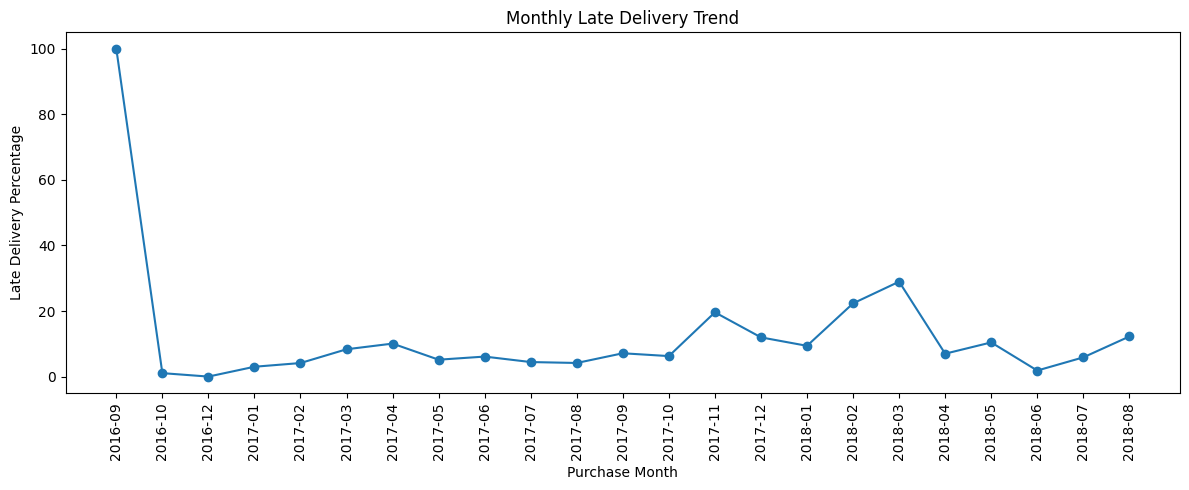

In [109]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_delivery["purchase_month"],
    monthly_delivery["Late_Delivery_Percentage"],
    marker="o"
)

plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Percentage")
plt.title("Monthly Late Delivery Trend")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [112]:
# Keep only the required columns from unhappy reviews
complaint_data = unhappy_reviews[
    ["order_id", "complaint_themes"]
].copy()

# Remove duplicate order-theme combinations
complaint_data = complaint_data.explode("complaint_themes")

complaint_data = complaint_data.dropna(
    subset=["complaint_themes"]
)

complaint_data = complaint_data.drop_duplicates(
    subset=["order_id", "complaint_themes"]
)

# Merge using order_id
theme_delivery = delivery_analysis.merge(
    complaint_data,
    on="order_id",
    how="inner",
    validate="many_to_many"
)

# Keep delivered orders only
theme_delivery = theme_delivery[
    theme_delivery["order_delivered_customer_date"].notna()
].copy()

print("Review-theme records:", len(theme_delivery))
print("Unique orders:", theme_delivery["order_id"].nunique())

display(theme_delivery.head())

Review-theme records: 8853
Unique orders: 6344


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,ai_sentiment,ai_confidence,customer_mood,...,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days,delivery_delay_days,delivery_performance,complaint_themes
0,58044bca115705a48fe0e00a21390c54,68e55ca79d04a79f20d4bfc0146f4b66,1,NaN,Sempre compro pela Internet e a entrega ocorre...,2018-04-08 00:00:00,2018-04-09 12:22:39,negative,0.815738,Unhappy,...,delivered,2018-03-16 12:51:35,2018-03-16 13:09:21,2018-03-20 18:32:31,2018-04-11 02:12:46,2018-04-06,25.556377,5.092199,Late,Delivery Issues
2,8b230a1373c6dc4bd867099fda1d7039,071251fe3b3493294536f03737a8a679,3,NaN,Eu comprei duas unidades e só recebi uma e ago...,2017-11-09 00:00:00,2017-11-10 10:38:37,negative,0.923624,Unhappy,...,delivered,2017-10-26 12:26:44,2017-10-28 02:56:07,2017-10-30 18:53:12,2017-11-08 20:24:42,2017-11-21,13.331921,-12.149514,On Time or Early,Missing Items
3,60c714ed14cef913944a3147094a4742,9ac05114800f02bfaa783bd76842dbe2,1,NaN,"Produto muito inferior, mal acabado.",2018-07-03 00:00:00,2018-07-05 19:03:52,negative,0.999502,Unhappy,...,delivered,2018-06-20 15:28:01,2018-06-21 15:39:14,2018-06-22 14:11:00,2018-07-02 14:38:57,2018-07-24,11.965926,-21.389618,On Time or Early,Product Quality
6,5c37d7ba6ef2f031c34bb4fda3454018,bbd1b9ebbc5a09d51caaa2d10e0f93b5,2,NaN,Demorou de mais pra entrega,2017-12-17 00:00:00,2017-12-17 12:14:13,negative,0.652303,Unhappy,...,delivered,2017-11-22 19:01:04,2017-11-24 19:12:30,2017-11-28 16:48:37,2017-12-27 17:58:53,2017-12-13,34.956817,14.749225,Late,Delivery Issues
7,46d8249ea59101c7288936c3e6f155d7,f25ddb6cd62d720a5d91fff80467930a,3,Entrega atrasou,A entrega foi dividida em duas. Não houve comu...,2018-01-20 00:00:00,2018-05-15 00:45:28,negative,0.529061,Unhappy,...,delivered,2018-01-13 13:19:46,2018-01-13 13:29:24,2018-01-16 18:51:43,2018-01-19 23:47:21,2018-03-08,6.435822,-47.008785,On Time or Early,Delivery Issues


In [113]:
theme_delivery_summary = (
    theme_delivery.groupby(
        ["delivery_performance", "complaint_themes"]
    )
    .size()
    .reset_index(name="Review_Count")
)

display(
    theme_delivery_summary.sort_values(
        ["delivery_performance", "Review_Count"],
        ascending=[True, False]
    )
)

,delivery_performance,complaint_themes,Review_Count
1,Late,Delivery Issues,1783
0,Late,Customer Service,462
6,Late,Product Quality,215
7,Late,Refund and Returns,102
5,Late,Product Information,38
2,Late,Missing Items,33
4,Late,Price and Value,30
3,Late,Packaging Issues,22
8,Late,Wrong Product,14
10,On Time or Early,Delivery Issues,1829


In [114]:
theme_delivery_summary["Group_Total"] = (
    theme_delivery_summary.groupby("delivery_performance")[
        "Review_Count"
    ].transform("sum")
)

theme_delivery_summary["Percentage"] = (
    theme_delivery_summary["Review_Count"]
    / theme_delivery_summary["Group_Total"] * 100
).round(2)

display(
    theme_delivery_summary.sort_values(
        ["delivery_performance", "Percentage"],
        ascending=[True, False]
    )
)

,delivery_performance,complaint_themes,Review_Count,Group_Total,Percentage
1,Late,Delivery Issues,1783,2699,66.06
0,Late,Customer Service,462,2699,17.12
6,Late,Product Quality,215,2699,7.97
7,Late,Refund and Returns,102,2699,3.78
5,Late,Product Information,38,2699,1.41
2,Late,Missing Items,33,2699,1.22
4,Late,Price and Value,30,2699,1.11
3,Late,Packaging Issues,22,2699,0.82
8,Late,Wrong Product,14,2699,0.52
10,On Time or Early,Delivery Issues,1829,6154,29.72


In [115]:
# Create one delivery record per order
order_delivery_lookup = orders[
    [
        "order_id",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].copy()

# Calculate delivery delay
order_delivery_lookup["delivery_delay_days"] = (
    pd.to_datetime(
        order_delivery_lookup["order_delivered_customer_date"],
        errors="coerce"
    )
    -
    pd.to_datetime(
        order_delivery_lookup["order_estimated_delivery_date"],
        errors="coerce"
    )
).dt.total_seconds() / 86400

# Assign delivery performance correctly
order_delivery_lookup["delivery_performance"] = np.select(
    [
        order_delivery_lookup["order_delivered_customer_date"].isna(),
        order_delivery_lookup["delivery_delay_days"] > 0
    ],
    [
        "Not Delivered",
        "Late"
    ],
    default="On Time or Early"
)

# Start with unhappy reviews and their complaint themes
complaint_review_data = unhappy_reviews[
    [
        "review_id",
        "order_id",
        "review_score",
        "complaint_themes"
    ]
].drop_duplicates(
    subset=["review_id", "order_id"]
).copy()

# Attach delivery information without expanding review records
complaint_review_data = complaint_review_data.merge(
    order_delivery_lookup[
        ["order_id", "delivery_performance"]
    ],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Keep delivered reviews
complaint_review_data = complaint_review_data[
    complaint_review_data["delivery_performance"].isin(
        ["Late", "On Time or Early"]
    )
].copy()

# Expand complaint themes
complaint_review_data = complaint_review_data.explode(
    "complaint_themes"
).dropna(subset=["complaint_themes"])

# Count distinct reviews for each theme
corrected_theme_summary = (
    complaint_review_data.groupby(
        ["delivery_performance", "complaint_themes"]
    )["review_id"]
    .nunique()
    .reset_index(name="Unique_Reviews")
)

# Calculate total distinct complaint reviews in each group
group_totals = (
    complaint_review_data.groupby("delivery_performance")[
        "review_id"
    ]
    .nunique()
    .rename("Group_Total")
)

corrected_theme_summary["Group_Total"] = (
    corrected_theme_summary["delivery_performance"]
    .map(group_totals)
)

corrected_theme_summary["Percentage"] = (
    corrected_theme_summary["Unique_Reviews"]
    / corrected_theme_summary["Group_Total"] * 100
).round(2)

display(
    corrected_theme_summary.sort_values(
        ["delivery_performance", "Unique_Reviews"],
        ascending=[True, False]
    )
)

,delivery_performance,complaint_themes,Unique_Reviews,Group_Total,Percentage
1,Late,Delivery Issues,1775,2053,86.46
0,Late,Customer Service,459,2053,22.36
6,Late,Product Quality,213,2053,10.38
7,Late,Refund and Returns,102,2053,4.97
5,Late,Product Information,38,2053,1.85
2,Late,Missing Items,33,2053,1.61
4,Late,Price and Value,30,2053,1.46
3,Late,Packaging Issues,22,2053,1.07
8,Late,Wrong Product,14,2053,0.68
10,On Time or Early,Delivery Issues,1797,4252,42.26


In [116]:
# 1. Prepare a clean delivery dataset
delivery_export = delivery_analysis.copy()

# Correctly label undelivered orders
delivery_export["delivery_performance"] = np.select(
    [
        delivery_export["order_delivered_customer_date"].isna(),
        delivery_export["delivery_delay_days"] > 0
    ],
    [
        "Not Delivered",
        "Late"
    ],
    default="On Time or Early"
)

# Add purchase month for Power BI trend analysis
delivery_export["purchase_month"] = (
    delivery_export["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

# 2. Prepare complaint theme details
complaint_export = complaint_review_data[
    [
        "review_id",
        "order_id",
        "review_score",
        "delivery_performance",
        "complaint_themes"
    ]
].copy()

complaint_export = complaint_export.rename(
    columns={"complaint_themes": "complaint_theme"}
)

# 3. Export all final datasets
delivery_export.to_csv(
    os.path.join(processed_path, "olist_delivery_review_analysis.csv"),
    index=False
)

complaint_export.to_csv(
    os.path.join(processed_path, "olist_complaint_theme_details.csv"),
    index=False
)

corrected_theme_summary.to_csv(
    os.path.join(processed_path, "olist_complaint_theme_summary.csv"),
    index=False
)

monthly_delivery.to_csv(
    os.path.join(processed_path, "olist_monthly_delivery_summary.csv"),
    index=False
)

# 4. Confirm the existing AI results file
ai_file = os.path.join(
    processed_path,
    "olist_ai_sentiment_results.csv"
)

print("AI results file exists:", os.path.exists(ai_file))

print("\nExported files:")
for file in [
    "olist_delivery_review_analysis.csv",
    "olist_complaint_theme_details.csv",
    "olist_complaint_theme_summary.csv",
    "olist_monthly_delivery_summary.csv"
]:
    print(file, "—", os.path.exists(os.path.join(processed_path, file)))

AI results file exists: True

Exported files:
olist_delivery_review_analysis.csv — True
olist_complaint_theme_details.csv — True
olist_complaint_theme_summary.csv — True
olist_monthly_delivery_summary.csv — True
